## This script calculate the topic similarity between international and non-international collaborated papers for **single authors**

In [41]:
import pandas as pd
import numpy as np
import itertools
from multiprocessing import Pool
from tqdm import tqdm
from scipy.spatial import distance
import random
import math
import seaborn as sns
import matplotlib.pyplot as plt
from adjustText import adjust_text

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [3]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [4]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

In [7]:
len(uids)

84162157

In [8]:
len(embedding)

84162157

### create an dict which records uid and the index in uids derived from embedding

In [9]:
uid_index_dict={}
n = 0
for uid in tqdm(uids):
    uid_index_dict[uid]=n
    n=n+1

100%|███████████████████████████| 84162157/84162157 [01:38<00:00, 851650.81it/s]


In [10]:
### authors who have international publications
author_intl = pub_all[pub_all.intl==1]['cluster_id'].unique()
author_intl_pubs = pub_all[pub_all.cluster_id.isin(author_intl)]

In [11]:
author_dict = {}
author_intl_pubs_array = author_intl_pubs[['cluster_id','intl','uid']].values
# Iterate through the dataframe rows
for row in tqdm(author_intl_pubs_array):
    key_A = row[0]
    key_B = row[1]
    value_C = row[2]
    
    # Check if the key_A already exists in the nested dictionary
    if key_A in author_dict:
        # Check if the key_B already exists for the key_A
        if key_B in author_dict[key_A]:
            # Append the value_C to the existing list
            author_dict[key_A][key_B].append(value_C)
        else:
            # Create a new key_B entry with a list containing value_C
            author_dict[key_A][key_B] = [value_C]
    else:
        # Create a new key_A entry with a nested dictionary containing key_B and value_C
        author_dict[key_A] = {key_B: [value_C]}

100%|███████████████████████████| 54939668/54939668 [02:14<00:00, 409983.61it/s]


In [12]:
author_intl_pubs.head()

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
0,29768068,40806321.0,CAN,F,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
2,29768068,53722752.0,CAN,L,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
3,29768070,65683243.0,JPN,F,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012
4,29768070,79129017.0,JPN,M,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012
5,29768070,58951927.0,CHN,M,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012


In [13]:
def return_embeddings(pubs,uid_index_dict,embedding):
    embed_index = []
    for pub in pubs:
        if pub in uid_index_dict:
            embed_index.append(uid_index_dict[pub])
    if len(embed_index)>0:
        embed_mean = np.mean(embedding[embed_index], axis=0)
        return embed_mean
    else:
        return np.zeros(64)

In [14]:
def cal_angle_dist(v1,v2):
    def dotproduct(v1, v2):
        return sum((a*b) for a, b in zip(v1, v2))
    
    def length(v):
        return math.sqrt(dotproduct(v, v))
    try:
        return math.acos(dotproduct(v1, v2) / (length(v1) * length(v2)))
    except ValueError:
        return np.zeros(64)

In [15]:
authors_similarity_res = []
for author in tqdm(author_dict.keys()):
    if 0 in author_dict[author] and 1 in author_dict[author]:
        dome_pub = author_dict[author][0]
        intl_pub = author_dict[author][1]
        
        dome_embeddings = return_embeddings(dome_pub, uid_index_dict,embedding)
        intl_embeddings = return_embeddings(intl_pub, uid_index_dict, embedding)
        
        if not np.all(dome_embeddings==0) and not np.all(intl_embeddings==0):
            cosine_dist = 1-distance.cosine(dome_embeddings, intl_embeddings)
            #angle_dist = cal_angle_dist(dome_embeddings, intl_embeddings)
            
            authors_similarity_res.append([author, cosine_dist, "cosine"])
            #authors_similarity_res.append([author,angle_dist, 'angular'])

100%|██████████████████████████████| 6757561/6757561 [08:43<00:00, 12917.11it/s]


In [16]:
author_simi = pd.DataFrame(authors_similarity_res, columns=['cluster_id','similarity','type'])
author_simi.head()

,cluster_id,similarity,type
0,40806321.0,0.988029,cosine
1,53722752.0,0.986672,cosine
2,65683243.0,0.756082,cosine
3,79129017.0,0.977163,cosine
4,9735544.0,0.950453,cosine


In [17]:
author_simi = author_simi[author_simi.similarity!='invalid angular']

In [18]:
author_cntry = author_intl_pubs[['cluster_id','cntry']].drop_duplicates()

In [19]:
author_simi = author_simi.merge(author_cntry, on='cluster_id')

In [20]:
author_simi

,cluster_id,similarity,type,cntry
0,40806321.0,0.988029,cosine,CAN
1,40806321.0,0.988029,cosine,GBR
2,53722752.0,0.986672,cosine,CAN
3,53722752.0,0.986672,cosine,DEU
4,53722752.0,0.986672,cosine,USA
...,...,...,...,...
3740919,46709489.0,0.683289,cosine,GBR
3740920,4020544.0,0.998449,cosine,AUS
3740921,84538276.0,0.792569,cosine,FRA
3740922,56265651.0,0.715068,cosine,PRT


In [21]:
cntry_simi = author_simi.groupby(['cntry','type'])['similarity'].mean().reset_index()

In [22]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [23]:
cntry_simi = cntry_simi.merge(stgroup_df, left_on='cntry', right_on='Code')

/tmp/ipykernel_918007/702851082.py:4: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='ST',y='similarity',data=cntry_simi,ax=ax, order=order, palette=color)


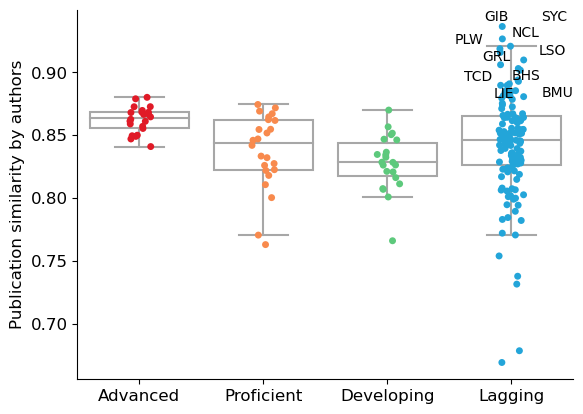

In [58]:
fig, ax=plt.subplots()
color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='similarity',data=cntry_simi,ax=ax, order=order, palette=color)
sns.boxplot(x='ST',y='similarity',data=cntry_simi,
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)
ax.set_ylabel("Publication similarity by authors", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cntrys_label = []
top20_df = cntry_simi.sort_values(by='similarity', ascending=False).head(10)
for index,row in top20_df.iterrows():
    cntrys_label.append(plt.text(3,row['similarity'],row['cntry']))
adjust_text(cntrys_label)
plt.savefig('../../data/dropbox/LaborDivision/figs/pub_similarity_derived_by_individual.pdf',bbox_inches='tight')

<Axes: xlabel='similarity', ylabel='Density'>

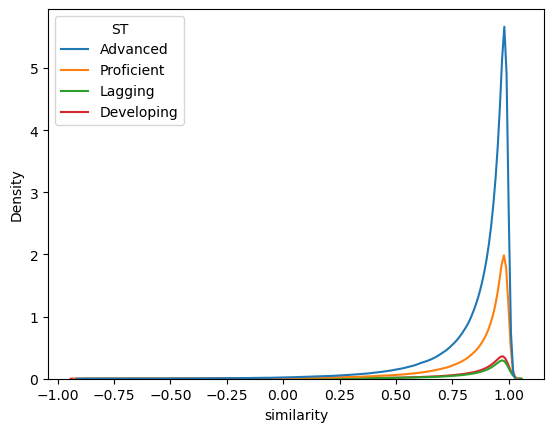

In [58]:
fig, ax = plt.subplots()
sns.kdeplot(x='similarity', hue='ST',data=author_simi, ax=ax)
#sns.histplot(x='similarity', data=author_simi[author_simi.ST=='Advanced'], ax=ax)

In [50]:
t1.sort_values(by='similarity')

,cluster_id,similarity,type,cntry
3703319,35697541.0,0.119374,cosine,NCL
3558419,36476201.0,0.195188,cosine,NCL
832250,1345213.0,0.284344,cosine,NCL
1414127,7046573.0,0.289961,cosine,NCL
1261361,15758545.0,0.301594,cosine,NCL
...,...,...,...,...
3123259,86435693.0,0.998635,cosine,NCL
16506,51183579.0,0.998672,cosine,NCL
485978,29822045.0,0.998750,cosine,NCL
2246886,8933048.0,0.999410,cosine,NCL


<Axes: xlabel='similarity', ylabel='Density'>

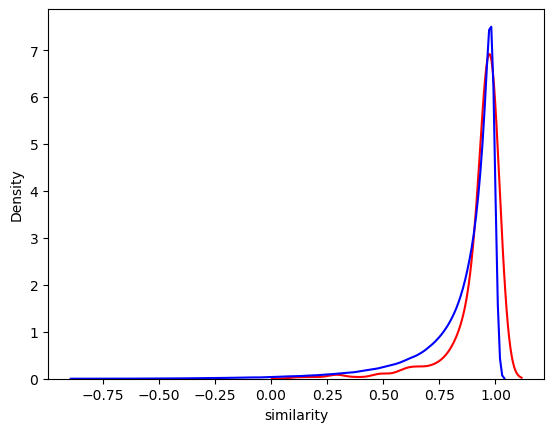

In [42]:
fig, ax = plt.subplots()
sns.kdeplot(x='similarity', data = t1, ax=ax, color='red')
sns.kdeplot(x='similarity', data=t2, ax=ax, color='blue')

In [36]:
author_intl_pubs[author_intl_pubs.cntry=='NCL']

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
19647,29787480,94179432.0,NCL,M,2008,73,Otolith chemical signature and growth of Chaet...,noalp,1,WOS:000257084000004
203412,29973158,54393192.0,NCL,F,2008,58,Real-Time PCR Detection of gyrA and parC Mutat...,noalp,1,WOS:000260305600048
203413,29973158,46698482.0,NCL,M,2008,58,Real-Time PCR Detection of gyrA and parC Mutat...,noalp,1,WOS:000260305600048
203414,29973158,26925819.0,NCL,M,2008,58,Real-Time PCR Detection of gyrA and parC Mutat...,noalp,1,WOS:000260305600048
203416,29973158,65489545.0,NCL,M,2008,58,Real-Time PCR Detection of gyrA and parC Mutat...,noalp,1,WOS:000260305600048
...,...,...,...,...,...,...,...,...,...,...
82113310,108711932,74862030.0,NCL,F,2019,18,Environmental versus operational drivers of dr...,noalp,1,WOS:000488223900008
82113313,108711932,52391264.0,NCL,M,2019,18,Environmental versus operational drivers of dr...,noalp,1,WOS:000488223900008
82113316,108711932,33329089.0,NCL,M,2019,18,Environmental versus operational drivers of dr...,noalp,1,WOS:000488223900008
82113317,108711932,69759817.0,NCL,L,2019,18,Environmental versus operational drivers of dr...,noalp,1,WOS:000488223900008


In [61]:
t1 = cntry_simi.sort_values(by='similarity',ascending=False).head(20)

In [80]:
t1.Code.tolist()

['SYC',
 'GIB',
 'NCL',
 'PLW',
 'GRL',
 'BHS',
 'LSO',
 'TCD',
 'BMU',
 'LIE',
 'CUW',
 'WSM',
 'SLB',
 'VUT',
 'CPV',
 'PAN',
 'GUY',
 'AND',
 'CAF',
 'AFG']

In [82]:
coll_ratio = pub_all[['ost_bk','cntry','intl']].drop_duplicates()

In [85]:
coll_ratio = coll_ratio.groupby(['cntry','intl']).size().reset_index()

In [87]:
coll_ratio = coll_ratio.pivot(index='cntry', columns='intl', values=0)

In [91]:
coll_ratio = coll_ratio.div(coll_ratio.sum(axis=1), axis=0).reset_index()

In [93]:
coll_ratio[coll_ratio.cntry.isin(t1.Code.tolist())]

intl,cntry,0,1
1,AFG,0.125000,0.875000
4,AND,0.019231,0.980769
19,BHS,0.129252,0.870748
23,BMU,0.095930,0.904070
30,CAF,0.073333,0.926667
40,CPV,0.009662,0.990338
43,CUW,0.072464,0.927536
68,GIB,0.136364,0.863636
75,GRL,0.070423,0.929577
77,GUY,0.177215,0.822785


In [96]:
test = cntry_simi.merge(coll_ratio, on='cntry')

<Axes: xlabel='similarity', ylabel='1'>

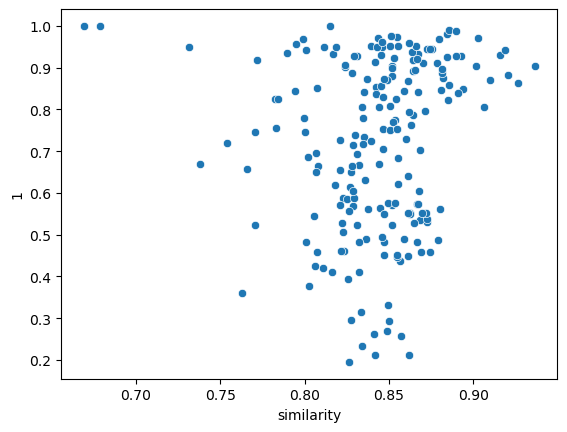

In [99]:
sns.scatterplot(x='similarity',y=1, data=test)

In [104]:
author_simi[author_simi.cntry=='STP']

,cluster_id,similarity,type,cntry,Code,ST
3727464,71787338.0,0.819857,cosine,STP,STP,Lagging
3727465,94272112.0,0.786152,cosine,STP,STP,Lagging
3727466,55562702.0,0.081280,cosine,STP,STP,Lagging
3727467,47028234.0,0.989382,cosine,STP,STP,Lagging


In [113]:
pub_all[(pub_all.cluster_id==71787338.0)]

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
13831,29781609,71787338.0,BRA,M,2008,82,Electrochemical and morphologic studies of nic...,noalp,0,WOS:000251644200008
144070,29913221,71787338.0,BRA,F,2008,3,Chelated minerals for poultry,single,0,WOS:000259783200001
728958,30509513,71787338.0,BRA,F,2008,66,Performance of Broilers Fed Diets Supplemented...,noalp,1,WOS:000259880300016
1100471,30896443,71787338.0,BRA,F,2008,3,Studies with sanguinarine like alkaloids as fe...,single,0,WOS:000258358200010
1262638,31065647,71787338.0,BRA,M,2008,66,"Body weight, carcass yield, and intestinal con...",noalp,0,WOS:000259230700007
...,...,...,...,...,...,...,...,...,...,...
72921843,101310837,71787338.0,BRA,M,2014,31,Cooperative upconversion luminescence in Tb3+:...,noalp,0,WOS:000331686400005
81101243,108155038,71787338.0,PRT,M,2019,8,Genetic characterization of green turtles (Che...,noalp,1,WOS:000480378700004
81167129,108186193,71787338.0,PRT,F,2014,18,Biochemical Indices and Life Traits of Loggerh...,noalp,1,WOS:000349144400061
81463361,108327085,71787338.0,PRT,M,2018,8,Stable isotopes reveal dietary differences and...,noalp,1,WOS:000441331700013


In [100]:
cntry_simi.sort_values(by='similarity')

,cntry,type,similarity,Code,ST
166,STP,cosine,0.669168,STP,Lagging
72,GNQ,cosine,0.678510,GNQ,Lagging
190,VCT,cosine,0.731493,VCT,Lagging
20,BIH,cosine,0.737762,BIH,Lagging
3,ALB,cosine,0.753897,ALB,Lagging
...,...,...,...,...,...
75,GRL,cosine,0.915778,GRL,Lagging
144,PLW,cosine,0.918718,PLW,Lagging
131,NCL,cosine,0.920719,NCL,Lagging
68,GIB,cosine,0.926526,GIB,Lagging


<Axes: xlabel='similarity', ylabel='Density'>

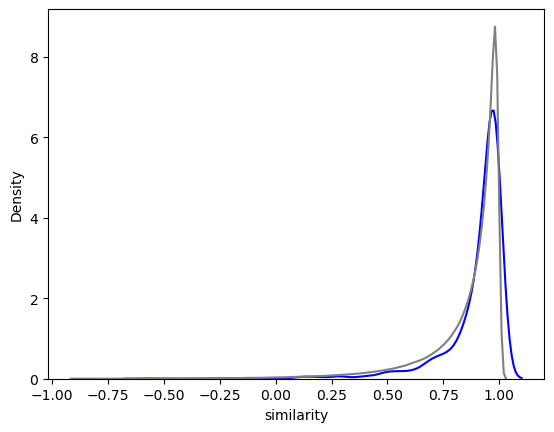

In [69]:
fig, ax=plt.subplots()
sns.kdeplot(x='similarity', data = author_simi[author_simi.cntry.isin(t1.cntry)], color='blue', ax=ax)
sns.kdeplot(x='similarity', data=author_simi[author_simi.ST=='Advanced'], color='gray', ax=ax)

In [137]:
authors = author_simi[author_simi.cntry.isin(t1.cntry)].cluster_id.tolist()

In [141]:
t = pub_all[pub_all.cluster_id.isin(authors)].drop_duplicates(subset=['cluster_id','cntry']).groupby(['cluster_id'])['cntry'].size()

In [150]:
author_cnt = author_cntry.groupby(['cluster_id'])['cntry'].size().reset_index(name='cntry_cnt')

In [152]:
author_cnt['affi_type'] = author_cnt['cntry_cnt'].apply(lambda x: "multi" if x>1 else "single")
author_cnt.head()

,cluster_id,cntry_cnt,affi_type
0,31.0,1,single
1,56.0,1,single
2,75.0,1,single
3,92.0,1,single
4,94.0,1,single


In [155]:
author_cnt = author_simi.merge(author_cnt, on='cluster_id')

In [167]:
affi_type = author_cnt.groupby(['cntry','affi_type']).size().reset_index(name='count')

In [168]:
affi_type = affi_type.pivot(index='cntry', columns='affi_type', values='count')
affi_type = affi_type.fillna(0)
affi_type = affi_type.div(affi_type.sum(axis=1), axis=0).reset_index()

In [170]:
cntry_simi.head(2)

,cntry,type,similarity,Code,ST
0,ABW,cosine,0.851499,ABW,Lagging
1,AFG,cosine,0.882240,AFG,Lagging


In [171]:
test = cntry_simi.merge(affi_type, on='cntry')

<Axes: xlabel='similarity', ylabel='multi'>

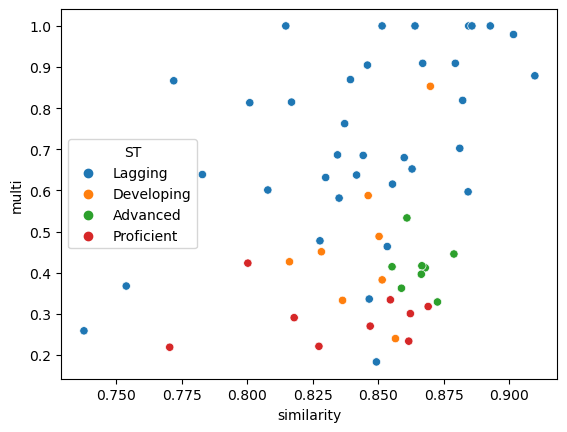

In [207]:
sns.scatterplot(x='similarity',y='multi', data=test.head(60),hue='ST')

In [206]:
test.sort_values(by='similarity', ascending=False).head(60)

,cntry,type,similarity,Code,ST,multi,single
172,SYC,cosine,0.936405,SYC,Lagging,0.865385,0.134615
68,GIB,cosine,0.926526,GIB,Lagging,0.750000,0.250000
131,NCL,cosine,0.920719,NCL,Lagging,0.797297,0.202703
144,PLW,cosine,0.918718,PLW,Lagging,0.833333,0.166667
75,GRL,cosine,0.915778,GRL,Lagging,0.855670,0.144330
19,BHS,cosine,0.909773,BHS,Lagging,0.878788,0.121212
108,LSO,cosine,0.905980,LSO,Lagging,0.775510,0.224490
174,TCD,cosine,0.902961,TCD,Lagging,0.923077,0.076923
23,BMU,cosine,0.901627,BMU,Lagging,0.979167,0.020833
106,LIE,cosine,0.893855,LIE,Lagging,0.715909,0.284091


In [193]:
author_simi[author_simi.cntry=='GNQ']

,cluster_id,similarity,type,cntry,Code,ST
3740902,41545696.0,0.920019,cosine,GNQ,GNQ,Lagging
3740903,25775374.0,0.522684,cosine,GNQ,GNQ,Lagging
3740904,1283046.0,0.807835,cosine,GNQ,GNQ,Lagging
3740905,59967915.0,0.924269,cosine,GNQ,GNQ,Lagging
3740906,34479326.0,0.552101,cosine,GNQ,GNQ,Lagging
3740907,35391244.0,0.905766,cosine,GNQ,GNQ,Lagging
3740908,81062532.0,0.165880,cosine,GNQ,GNQ,Lagging
3740909,73391495.0,0.535002,cosine,GNQ,GNQ,Lagging
3740910,10920507.0,0.564803,cosine,GNQ,GNQ,Lagging
3740911,70481439.0,0.886745,cosine,GNQ,GNQ,Lagging


In [196]:
author_simi[author_simi.cntry=='GIB'].sort_values(by='similarity')

,cluster_id,similarity,type,cntry,Code,ST
3740419,67695567.0,0.793967,cosine,GIB,GIB,Lagging
3740420,69826567.0,0.793967,cosine,GIB,GIB,Lagging
3740416,10254055.0,0.888466,cosine,GIB,GIB,Lagging
3740417,19965566.0,0.894081,cosine,GIB,GIB,Lagging
3740411,80970122.0,0.910918,cosine,GIB,GIB,Lagging
3740414,3308961.0,0.961203,cosine,GIB,GIB,Lagging
3740418,25976278.0,0.967776,cosine,GIB,GIB,Lagging
3740415,39017095.0,0.969212,cosine,GIB,GIB,Lagging
3740409,59956166.0,0.976323,cosine,GIB,GIB,Lagging
3740413,71293443.0,0.981347,cosine,GIB,GIB,Lagging


<Axes: xlabel='similarity', ylabel='Count'>

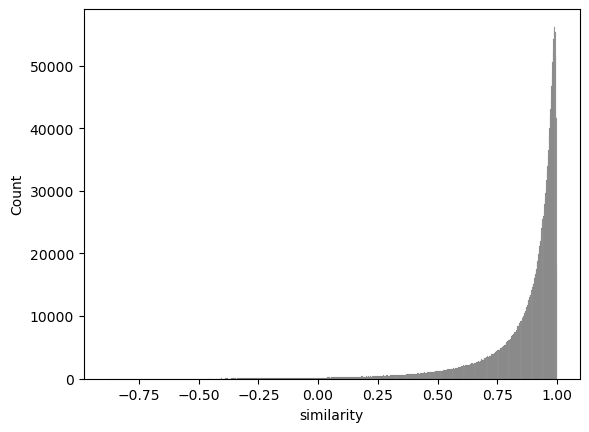

In [68]:
sns.histplot(x='similarity', data=author_simi[author_simi.ST=='Advanced'], color='gray')

/tmp/ipykernel_617064/3158715848.py:4: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='ST',y='similarity',data=cntry_simi,ax=ax, order=order, palette=color)


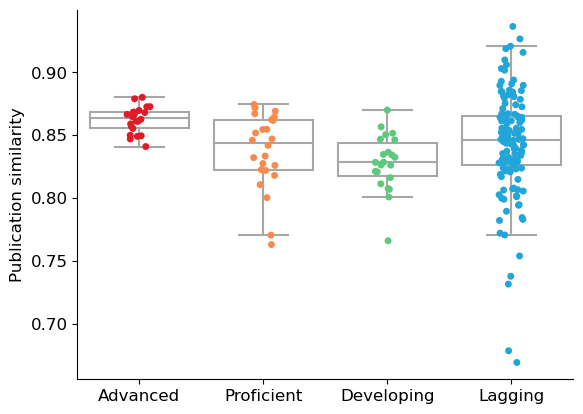

In [30]:
fig, ax=plt.subplots()
color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='similarity',data=cntry_simi,ax=ax, order=order, palette=color)
sns.boxplot(x='ST',y='similarity',data=cntry_simi,
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)
ax.set_ylabel("Publication similarity", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

In [139]:
cosine = cntry_simi[cntry_simi.type=='cosine']

In [151]:
cosine.sort_values(by='similarity').tail(30)

,cntry,type,similarity,Code,ST
233,MDV,cosine,0.874119,MDV,Lagging
395,ZAF,cosine,0.874358,ZAF,Proficient
211,LCA,cosine,0.87527,LCA,Lagging
153,GTM,cosine,0.878447,GTM,Lagging
19,AUS,cosine,0.878899,AUS,Advanced
25,BDI,cosine,0.879433,BDI,Lagging
273,NOR,cosine,0.880055,NOR,Advanced
125,FRO,cosine,0.880599,FRO,Lagging
75,COG,cosine,0.881132,COG,Lagging
343,SWZ,cosine,0.88152,SWZ,Lagging


In [152]:
t = author_intl_pubs[author_intl_pubs.cntry=='GIB']